In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S .
    !cmake --build build
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/1
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))
    print("✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。")

✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。


# 第1章 PCの仕組みとハローワールド — 1.6 とにかく手を動かそう (*Hands-On Empirical Mindset & Binary Mutation*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/1/1.6_Hands_On_Mindset.ipynb)

---

## 🎯 本節の学習目標と技術的動機

前節（1.5 節「結局、何をやったのか？」）では、CPU の電源投入（Power-On Reset）からリセットベクタ（Reset Vector: `0xFFFFFFF0`）、UEFI PI 5大ブートフェーズ（SEC → PEI → DXE → BDS → TSL）、そして標準探索パス（`\EFI\BOOT\BOOTX64.EFI`）を経て `EfiMain` が呼び出されるまでの全容を理論的に解剖しました。

しかし、1.1 節でバイナリエディタを使って初めてハローワールドを動かした際、多くの学習者が**「なんとなく言われた通りに入力したら動いたけれど、本当は何が起きているのか実感として腑に落ちていない」**というモヤモヤした感覚を抱いたはずです。

本節（1.6 節「とにかく手を動かそう」）の最大の目的は、**「低レイヤ・OS自作における最強の学習哲学：実験と観察の OODA ループ」**を身体感覚として体得することです。

> [!IMPORTANT]
> **低レイヤ学習の黄金律**:
> 巨大で難解なハードウェア仕様書（Intel SDM や UEFI Specification など数千ページ）を最初から完全に暗記しようとすると、確実に挫折します。
> OS自作を成功させるエンジニアは、**「ブラックボックスを恐れず、最小のコードやバイナリの一部を手動で書き換えて（変異/Mutation）、その結果画面やCPUがどう壊れるかを観察する」**というボトムアップな仮説検証サイクルを回しています。

本ノートブックでは、1.1 節で作成した最小 UEFI アプリケーション（`hello.efi`）を対象に、**バイナリ直接改変（Binary Patching）実験**をステップ・バイ・ステップで実行し、低レイヤのメモリ構造・UTF-16LE 終端規則・機械語制御フローの真実を浮き彫りにします。

---

## 1. 低レイヤ学習の極意：実験と観察の OODA ループ (*Empirical OODA Loop*)

OS 自作や組み込み開発、デバイスドライバ構築といった低レイヤプログラミングでは、通常の Web 開発やアプリ開発のように親切なスタックトレースやエラーログ（`Exception in thread "main"` など）は出力されません。バグが生じた瞬間、画面は真っ暗のまま停止（Triple Fault や Hang）するか、PC が即座に再起動します。

このような過酷な環境で生き残るための思考フレームワークが、米空軍のジョン・ボイド大佐が提唱した軍事意思決定理論 **OODA ループ (*Observe-Orient-Decide-Act*)** の適用です。

```mermaid
flowchart TD
    subgraph OODA_Loop ["低レイヤ開発における実験・観察 OODA ループ"]
        direction TB
        OBS["1. 観察 (Observe)<br/>・画面出力の文字列・文字化け<br/>・QEMU モニタ (info registers)<br/>・バイナリの 16進ダンプ"]
        ORI["2. 方向付け (Orient / 仮説形成)<br/>・UTF-16LE は 2バイト単位<br/>・ヌル文字 '\0\0' が終端条件<br/>・jmp $ (EB FE) が停止の要"]
        DEC["3. 意思決定 (Decide / パッチ設計)<br/>・書き換えるオフセットの特定<br/>・注入バイト列のエンコード<br/>・期待される壊れ方の予測"]
        ACT["4. 行動 (Act / 実験実行)<br/>・バイナリエディタでバイト書換<br/>・QEMU / 実機でブート<br/>・結果の差分判定"]
        
        OBS --> ORI --> DEC --> ACT --> OBS
    end
    
    style OBS fill:#E3F2FD,stroke:#1565C0,stroke-width:2px;
    style ORI fill:#E8F5E9,stroke:#2E7D32,stroke-width:2px;
    style DEC fill:#FFF3E0,stroke:#E65100,stroke-width:2px;
    style ACT fill:#F3E5F5,stroke:#6A1B9A,stroke-width:2px;
```

### なぜ「壊してみる」ことが最速の理解に繋がるのか？
正常に動作しているシステムを見ているだけでは、**「どのパーツが何の役割を果たしているのか」**を区別できません。
しかし、特定の1バイトだけを意図的に破壊（変異 / Mutation）すると：
1. **壊れなかった場合**: そのバイトはパディング（余白）や不要なメタデータであると推測できる。
2. **文字の後ろにゴミが表示された場合**: そのバイトが「文字列の終端（ヌルターミネータ）」を示していたことが証明される。
3. **CPU が即死・ハングした場合**: そのバイトが「実行フローを繋ぎ止める制御命令（無限ループ等）」であったことが確定する。

このように、**「壊し方を観察することで、正常動作を支えていた不可視の前提条件を炙り出す」**手法こそが、ハッカー・システムプログラマの真髄です。

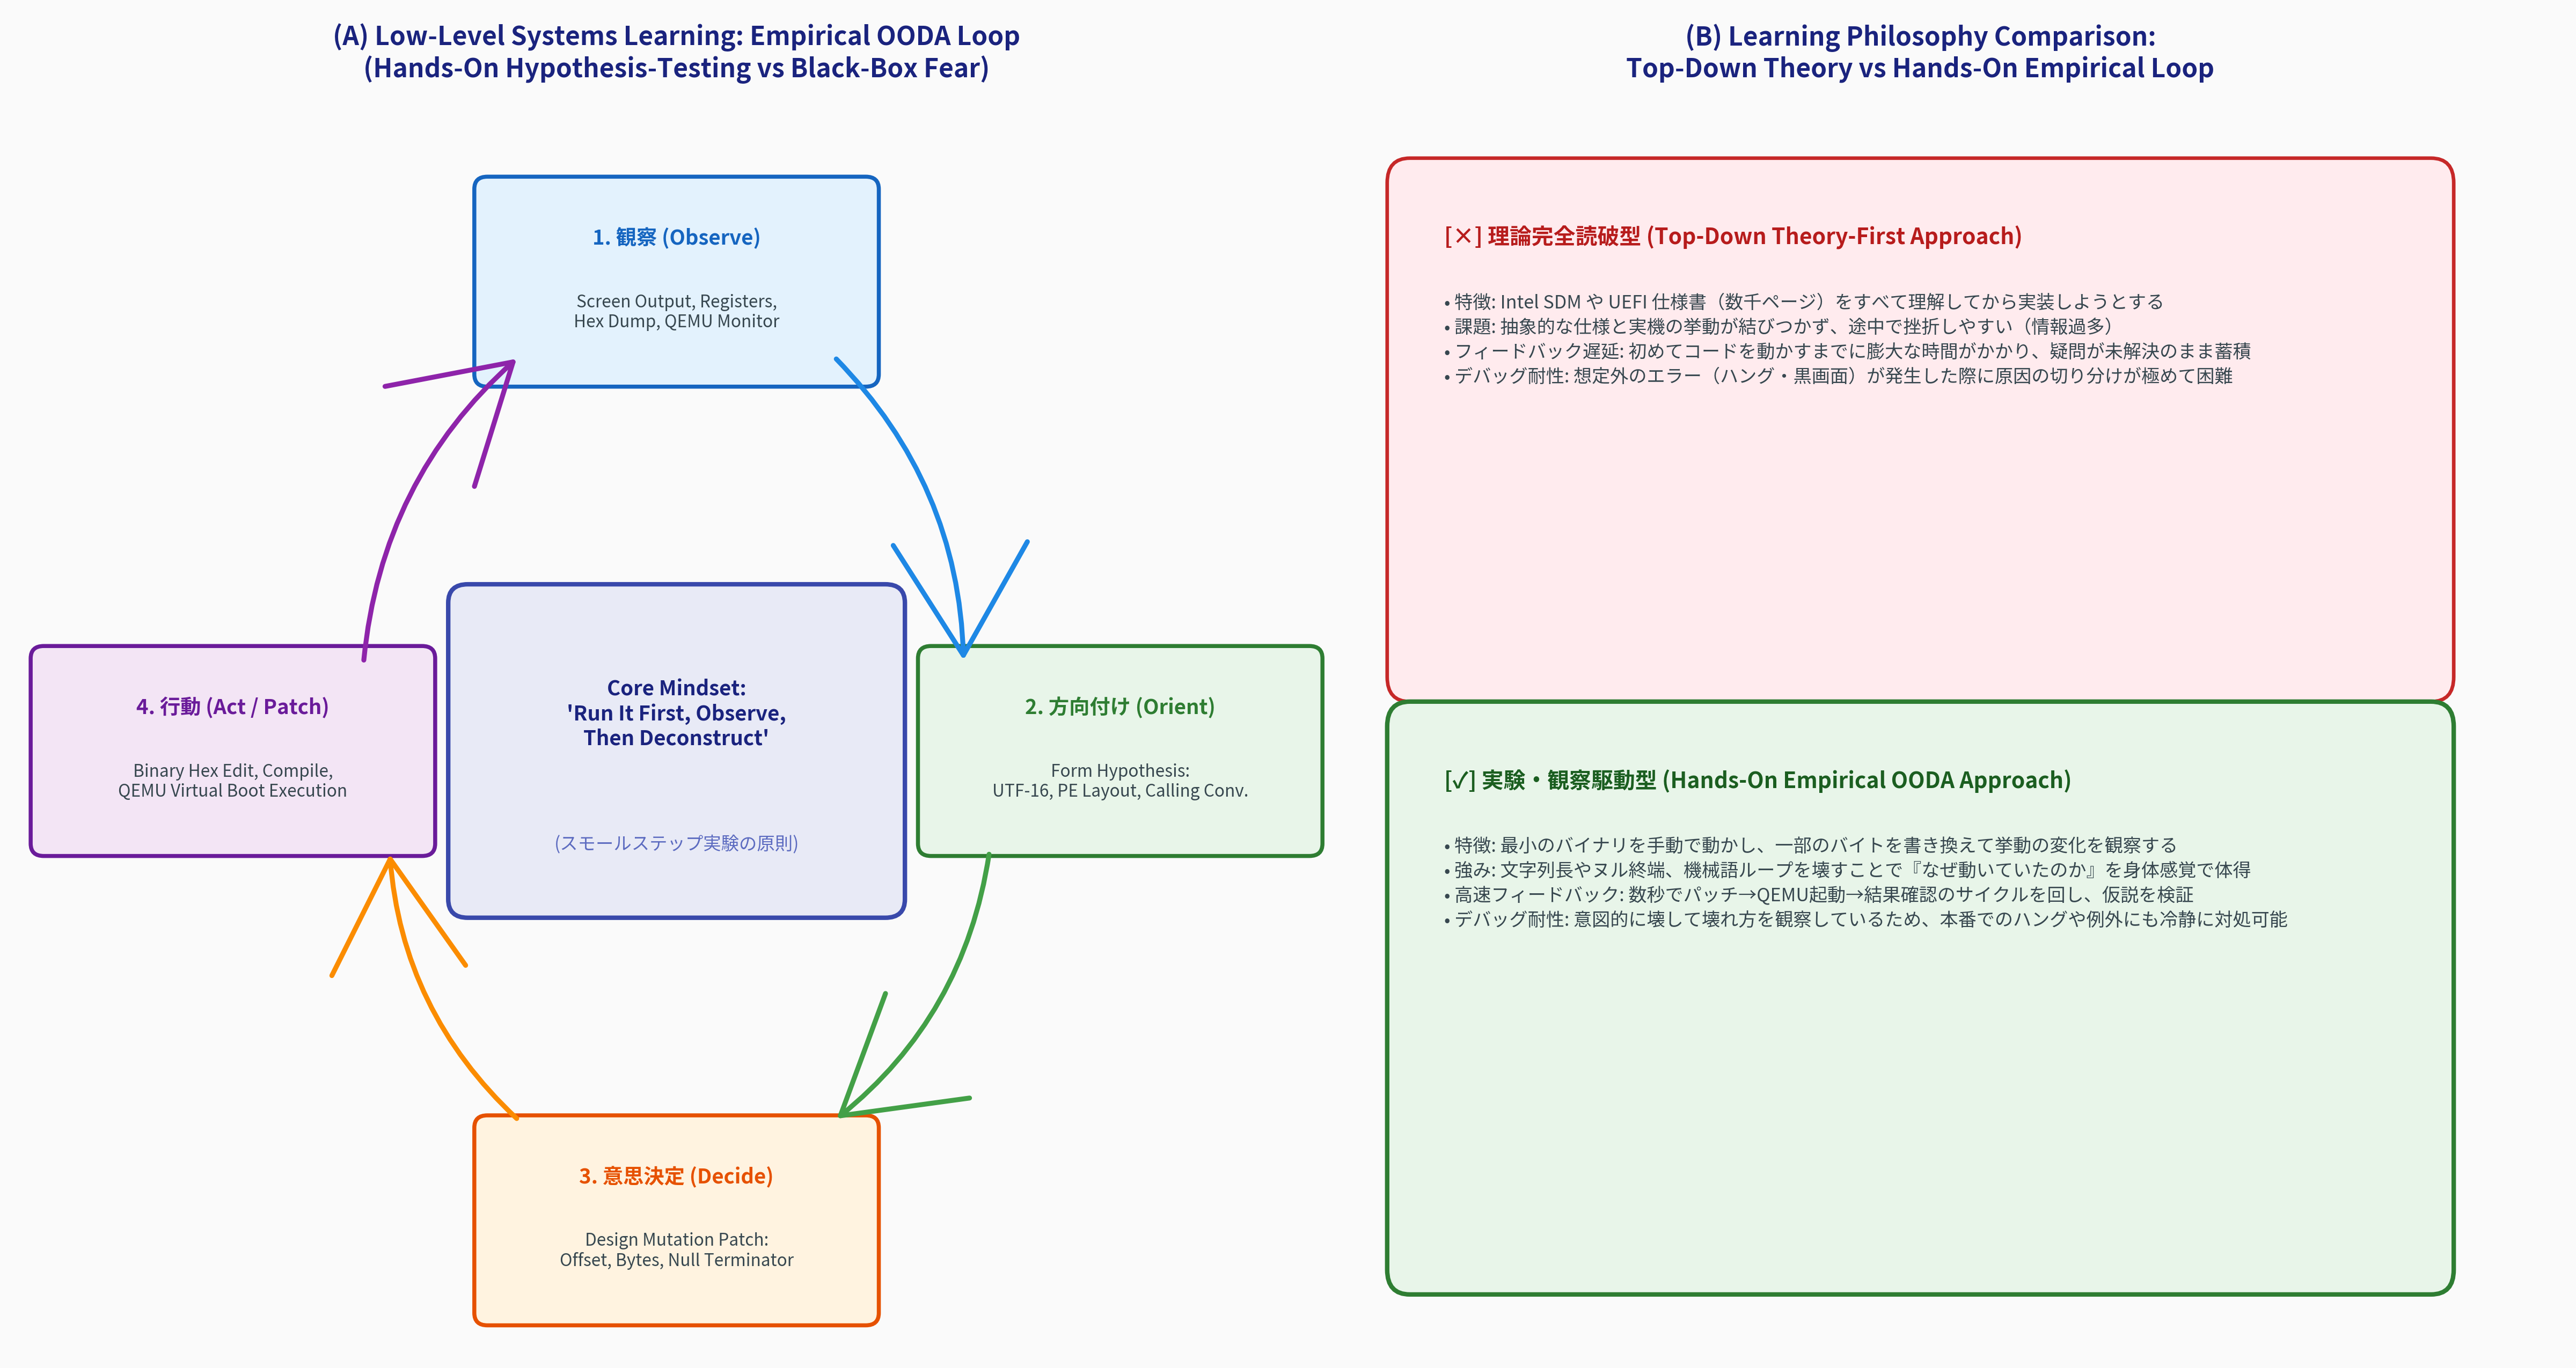

In [2]:
# 高解像度アーキテクチャ図版: 実験・観察 OODA ループと学習哲学の比較
from pathlib import Path
from IPython.display import Image, display
from common import plot_hands_on_experiment_cycle

repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
fig_path = plot_hands_on_experiment_cycle(str(repo_root / "1/result/fig1_11_hands_on_experiment_cycle.png"))
display(Image(filename=fig_path, width=850))

---

## 2. PE32+ バイナリ構造の解剖と改変ターゲット領域 (*Binary Mutation Anatomy*)

1.1 節で作成した最小 UEFI アプリケーション `BOOTX64.EFI`（`vendor/mikanos-build/day01/bin/hello.efi`）のファイルサイズはちょうど **1,536 バイト (0x600 バイト)** です。

この 1,536 バイトは、以下のように 512 バイト（0x200 バイト）ごとの 3 つの領域に分割されています：

```text
+-------------------------------------------------------------------------+
| [領域 1] 0x0000 - 0x01FF (512 Bytes): DOS & PE32+ ヘッダ                |
|  - 0x000: DOS Magic "MZ" (0x5A4D)                                       |
|  - 0x03C: PEヘッダへのオフセット (0x00000080)                            |
|  - 0x080: PE Signature "PE\0\0" (0x00004550)                           |
|  - セクションヘッダ表: .text (コード) & .data (データ)                    |
+-------------------------------------------------------------------------+
| [領域 2] 0x0200 - 0x03FF (512 Bytes): Section .text (機械語コード)       |
|  - 0x200: EfiMain エントリポイント                                      |
|  - 0x200: sub rsp, 0x28 (Microsoft x64 32B Shadow Space + 8B アライメント)|
|  - 0x204: mov rcx, [rdx + 64] (SystemTable->ConOut ポインタ取得)       |
|  - 0x208: lea rdx, [rel .msg] (表示文字列のアドレス設定)               |
|  - 0x20F: call [rcx + 8] (ConOut->OutputString 関数ポインタ間接呼び出し)|
|  ★ 0x212: jmp .fin (0xEB, 0xFE: 相対ジャンプ -2バイトの無限ループ)     |
|  - 0x214 - 0x3FF: 0x00 パディング領域                                   |
+-------------------------------------------------------------------------+
| [領域 3] 0x0400 - 0x05FF (512 Bytes): Section .data / .rdata (文字列)   |
|  ★ 0x400: UTF-16LE 文字列 "Hello, world!\0" (28 Bytes)                 |
|    H=0x0048, e=0x0065, l=0x006C, l=0x006C, o=0x006F, ,=0x002C, ...     |
|    Terminator: 0x0000 (2バイトのヌル終端)                               |
|  - 0x41C - 0x5FF: 0x00 パディング領域                                   |
+-------------------------------------------------------------------------+
```

### 本節で実行する 4 大変異実験 (The 4 Mutation Experiments)
本節では、バイナリの以下の 2 大ターゲットを意図的に改変します：
1. **Target A: 文字列データ領域 (オフセット `0x400`)**
   - **Case 1 (同一長置換)**: "Hello, world!" (13文字) を "Hello, Mikan!" (13文字) に書き換える。
   - **Case 2 (ヌル文字欠落短縮)**: "Hi!" (3文字) を上書きするが、終端 `0x0000` を付与しない。
   - **Case 3 (セクション超過オーバーフロー)**: 300文字超（600B以上）の巨大文字列を注入し、ファイルサイズ境界を破壊する。
2. **Target B: 機械語無限ループ (オフセット `0x212`)**
   - **Case 4 (無限ループ破壊)**: `jmp $` (`0xEB, 0xFE`) を `NOP` (`0x90, 0x90`) に書き換え、強制的にループを脱出させる。

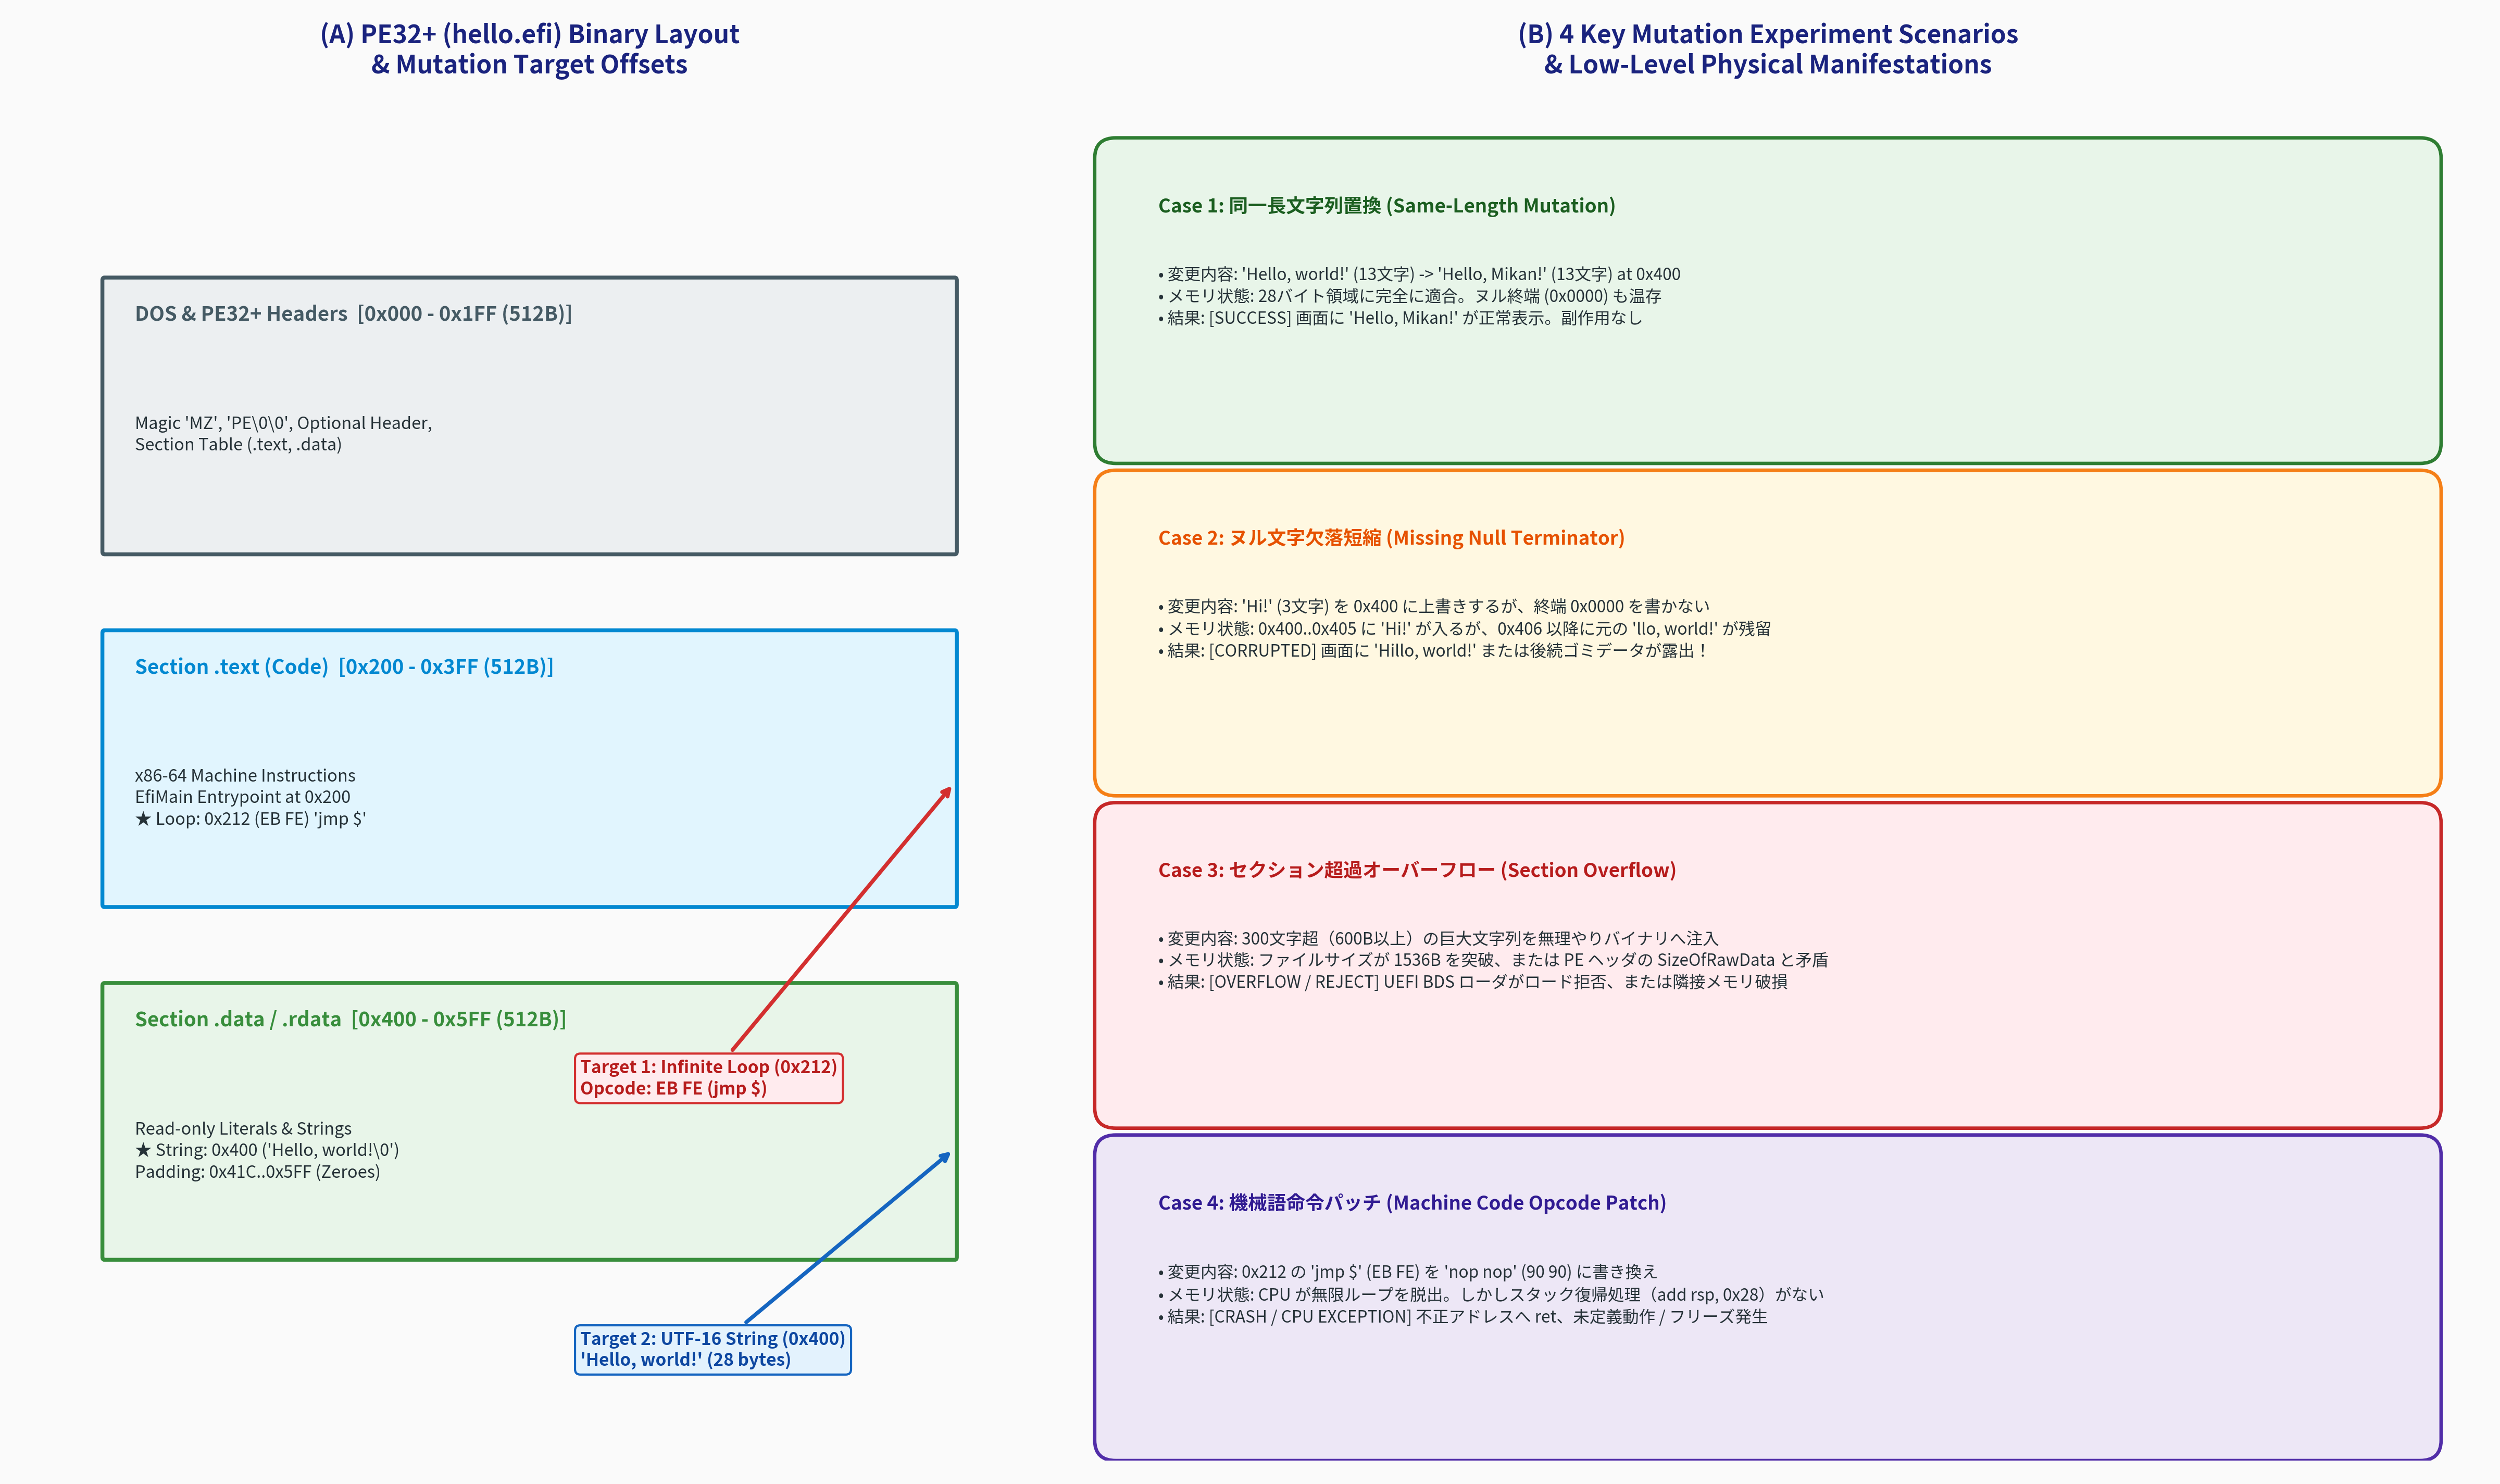

In [3]:
# 高解像度アーキテクチャ図版: PE32+ バイナリ改変ターゲットと 4 大変異実験の解剖図
from pathlib import Path
from IPython.display import Image, display
from common import plot_binary_mutation_anatomy

repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
fig_path = plot_binary_mutation_anatomy(str(repo_root / "1/result/fig1_12_binary_mutation_anatomy.png"))
display(Image(filename=fig_path, width=850))

---

## 3. 実験 1 & 2: UTF-16LE 文字列の書き換えとヌル終端の決定打 (*String Mutation & Null Termination*)

### 3.1 実験 1: 同一長文字列置換 (Same-Length Mutation)
まずは最も安全で基本となる改変です。
元の文字列は `"Hello, world!"`（13文字）です。
これをまったく同じ文字数の `"Hello, Mikan!"`（13文字）に書き換えます。

UEFI の文字列は **UTF-16 Little Endian (UTF-16LE)** で表現されるため、各 ASCII 文字は `[下位8bit, 上位8bit (0x00)]` の 2 バイトで格納されます：

$$
\text{Offset } 0\text{x}400: \quad \underbrace{48\,00}_{\text{'H'}} \; \underbrace{65\,00}_{\text{'e'}} \; \underbrace{6C\,00}_{\text{'l'}} \; \underbrace{6C\,00}_{\text{'l'}} \; \underbrace{6F\,00}_{\text{'o'}} \; \underbrace{2C\,00}_{\text{','}} \; \underbrace{20\,00}_{\text{' '}} \; \underbrace{77\,00}_{\text{'w'}} \dots
$$

変更箇所は後半の 7 文字目以降 `"world!"` $\rightarrow$ `"Mikan!"` です：
- `'w'` (0x0077) $\rightarrow$ `'M'` (0x004D)
- `'o'` (0x006F) $\rightarrow$ `'i'` (0x0069)
- `'r'` (0x0072) $\rightarrow$ `'k'` (0x006B)
- `'l'` (0x006C) $\rightarrow$ `'a'` (0x0061)
- `'d'` (0x0064) $\rightarrow$ `'n'` (0x006E)

全体のバイト長は変わらず、末尾の `0x0000`（ヌル終端）もそのまま残るため、UEFI ファームウェアは寸分違わず綺麗に `"Hello, Mikan!"` を表示します。

---

### 3.2 実験 2: ヌル文字欠落短縮 (Missing Null Terminator)
次に、文字列を短くしようとして `"Hi!"`（3文字）をオフセット `0x400` に書き込む実験を考えます。
初心者が陥りがちな罠が、**「3文字分（6バイト: `48 00 69 00 21 00`）だけを書き換えて、ヌル終端 `00 00` を書かない」**というミスです。

このとき、メモリ上では何が起きるでしょうか？

```text
書き換え前 (Original):
  0x400: [H ][e ][l ][l ][o ][, ][  ][w ][o ][r ][l ][d ][! ][ ]
  Bytes: 4800 6500 6C00 6C00 6F00 2C00 2000 7700 6F00 7200 6C00 6400 2100 0000

書き換え後 (Patch "Hi!" only without   ):
  0x400: [H ][i ][! ][l ][o ][, ][  ][w ][o ][r ][l ][d ][! ][ ]
         ^^^^^^^^^^^  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
         書き換えた3文字   元のメモリデータがそのまま残留！
```

`OutputString` 関数は引数ポインタから **`0x0000`（ヌル終端）が出現するまで画面に文字を出力し続ける仕様** になっています。
その結果、画面には `"Hi!"` だけでなく、書き換えられずに残った古い文字列が結合され、
$$\text{画面表示} = \mathbf{\text{"Hi!lo, world!"}}$$
という奇妙な文字列が現れます！

> [!CAUTION]
> **メモリ残留露出の危険性**:
> もし元のバッファにヌル文字が存在しなかった場合、CPU はセクション後方のパディング領域や、最悪の場合は隣接する未割り当てメモリまで読み進めてしまいます。これは低レイヤにおける典型的な**情報漏洩（Information Disclosure）脆弱性**や**セグメンテーション違反（Page Fault）**の根源です。

In [4]:
# Python によるバイナリ変異シミュレーション (Case 1 & Case 2)
from common import BinaryMutator, MutationOutcome
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
bin_path = repo_root / "vendor/mikanos-build/day01/bin/hello.efi"
raw_bytes = bin_path.read_bytes()

# === 実験 1: 同一長置換 ("Hello, Mikan!") ===
mutator_case1 = BinaryMutator(raw_bytes)
patch1_bytes = BinaryMutator.encode_utf16le("Hello, Mikan!", null_terminate=True)
mutator_case1.apply_patch(0x400, patch1_bytes, "Case 1: Same-length replace")

res1 = mutator_case1.simulate_execution()
print("=" * 65)
print("【実験 1: 同一長文字列置換】")
print(f"  結果ステータス : {res1['outcome'].value}")
print(f"  画面出力文字列 : \"{res1['screen_output']}\"")
print(f"  CPU 実行状態   : {res1['cpu_state']}")
print("\n[バイナリ差分テーブル (HexDiff)]")
print(mutator_case1.format_diff_table(max_entries=6))

# === 実験 2: ヌル文字欠落短縮 ("Hi!") ===
mutator_case2 = BinaryMutator(raw_bytes)
patch2_bytes = BinaryMutator.encode_utf16le("Hi!", null_terminate=False)
mutator_case2.apply_patch(0x400, patch2_bytes, "Case 2: Shortened without \\0\\0")

res2 = mutator_case2.simulate_execution()
print("=" * 65)
print("【実験 2: ヌル文字欠落短縮】")
print(f"  結果ステータス : {res2['outcome'].value}")
print(f"  画面出力文字列 : \"{res2['screen_output']}\"  <-- 古い文字列が残留露出！")
print(f"  診断メッセージ : {res2['message']}")

【実験 1: 同一長文字列置換】
  結果ステータス : SUCCESS
  画面出力文字列 : "Hello, Mikan!"
  CPU 実行状態   : HALTED (Looping at 0x212)

[バイナリ差分テーブル (HexDiff)]
Offset (Hex) | Original Byte | Patched Byte | Description
-------------+---------------+--------------+----------------------
0x00040E   | 0x77 ('w')   | 0x4D ('M')   | diff
0x000410   | 0x6F ('o')   | 0x69 ('i')   | diff
0x000412   | 0x72 ('r')   | 0x6B ('k')   | diff
0x000414   | 0x6C ('l')   | 0x61 ('a')   | diff
0x000416   | 0x64 ('d')   | 0x6E ('n')   | diff
【実験 2: ヌル文字欠落短縮】
  結果ステータス : SUCCESS
  画面出力文字列 : "Hi!lo, world!"  <-- 古い文字列が残留露出！
  診断メッセージ : String successfully mutated to 'Hi!lo, world!'.


---

## 4. 実験 3: セクションサイズ超過とアライメント境界破壊 (*Section Overflow & Alignment Violation*)

次に、文字列を大幅に長くして 300 文字（600 バイト）以上の巨大なテキストを無理やり注入する実験を考えます。

PE32+ 形式の実行可能ファイルでは、ヘッダ内のセクションテーブルに以下の 2 大サイズが厳密に記録されています：
1. **`VirtualSize`**: メモリロード時に割り当てられる仮想アドレス空間のバイトサイズ
2. **`SizeOfRawData`**: ファイル上に物理的に記録されている生データのバイトサイズ（通常 `FileAlignment: 512B` の整数倍）

```mermaid
flowchart LR
    subgraph File_Layout ["ディスク上ファイル配置 (hello.efi: 1536B)"]
        HDR["Headers<br/>(0x000..0x1FF)"]
        TXT["Section .text<br/>(0x200..0x3FF)"]
        DAT["Section .data<br/>(0x400..0x5FF)"]
        HDR --- TXT --- DAT
    end

    subgraph Overflow_Attempt ["巨大データ注入による破壊"]
        DAT_OVF["Section .data (0x400..0x7FF)<br/>★ 1536バイト境界を突破！<br/>ヘッダ記載の RawSize と矛盾"]
    end

    DAT -.->|注入| DAT_OVF
    style DAT_OVF fill:#FFEBEE,stroke:#C62828,stroke-width:2px;
```

もしヘッダを更新せずに物理ファイルサイズだけを勝手に拡張したり、`.data` セクションの許容量を超えてデータを書き込むと：
- **UEFI BDS ローダの検証エラー**: PE ヘッダのチェックサムや `SizeOfImage` と物理サイズが一致せず、ファームウェアが `EFI_LOAD_ERROR`（ロード失敗）を返して起動を拒否します。
- **隣接メモリ破壊**: 仮にロードされたとしても、後続の UEFI スタックやヒープ領域を破壊し、未定義動作（Triple Fault）に至ります。

In [5]:
# Python によるセクション溢れ・ロード拒否シミュレーション (Case 3)
mutator_case3 = BinaryMutator(raw_bytes)
oversized_payload = b"A" * 300  # 1500バイト地点から300バイト注入 -> 1800バイトに拡張
mutator_case3.apply_patch(1500, oversized_payload, "Case 3: Section Overflow Payload")

res3 = mutator_case3.simulate_execution()
print("=" * 65)
print("【実験 3: セクション超過オーバーフロー】")
print(f"  変更後バイナリサイズ : {len(mutator_case3.current_bytes)} バイト (基準: 1536 バイト)")
print(f"  結果ステータス       : {res3['outcome'].value}")
print(f"  CPU / BDS 状態       : {res3['cpu_state']}")
print(f"  診断メッセージ       : {res3['message']}")

【実験 3: セクション超過オーバーフロー】
  変更後バイナリサイズ : 1800 バイト (基準: 1536 バイト)
  結果ステータス       : SECTION_OVERFLOW
  CPU / BDS 状態       : CRASH / UEFI_LOAD_ERROR
  診断メッセージ       : Binary size 1800 bytes exceeds raw section/file capacity (1536 bytes). UEFI BDS loader rejects the malformed PE32+ image or corrupts adjacent memory.


---

## 5. 実験 4: 機械語コードの改変と CPU 例外・スタック破壊 (*Opcode Mutation & CPU Fault*)

最後に、データ（文字列）ではなく **機械語コード領域（`.text`）** を意図的に改変する実験を行います。

1.1 節で確認した通り、`hello.efi` のエントリポイント `EfiMain` は、画面に文字列を表示した後、オフセット `0x212` で以下の命令を実行しています：

```nasm
.fin:
    jmp .fin    ; オフセット 0x212: 機械語 EB FE (相対ジャンプ -2 バイト)
```

この `EB FE` は、CPU に「現在のアドレスから 2 バイト戻れ（つまり自分自身にジャンプしろ）」と命じる **無限ループ（Infinite Loop）** です。
これによって CPU は暴走せず、文字が表示された状態でその場に停止し続けます。

### 実験: 無限ループ `EB FE` を `NOP` (`90 90`) に変えたらどうなるか？
「画面に文字が出たのだから、無限ループを解除して関数から正常終了（return）させたい」と考え、`0x212` の 2 バイトを `NOP` (`0x90 0x90`: 何もしない命令) に書き換えてみましょう。

しかし、ここには**低レイヤ特有の致命的な落とし穴**が存在します：

```text
EfiMain 関数のプロローグ:
  0x200: sub rsp, 0x28    ; スタックポインタ RSP を 40バイト引き下げて領域確保

もし無限ループを NOP で通り抜けたら:
  0x214: 00 00 00 00 ...  ; 後続の 0x00 パディングを実行 (add [rax], al など)
  最悪の場合:
  ret (0xC3) を実行しようとするが、スタックポインタ RSP が 0x28 バイトずれたまま！
  -> 呼び出し元アドレスではなく、ローカル変数のゴミを RIP にロードして大暴走！
```

C言語の関数呼び出し規約（Microsoft x64 ABI）では、関数から抜ける前に **`add rsp, 0x28` を実行してスタックポインタを正確に戻す義務** があります。
プロローグで動かしたスタックを戻さずにリターン命令を実行すると、CPU はスタック上に残った無関係な数値を戻り先アドレス（RIP）と誤認し、未割り当て領域にジャンプして **一般保護例外 (#GP: General Protection Fault)** や **トリプルフォールト（即時再起動）** を引き起こします！

In [6]:
# Python による機械語改変と CPU 挙動シミュレーション (Case 4)
mutator_case4 = BinaryMutator(raw_bytes)
# オフセット 0x212 の 'jmp $' (EB FE) を 'nop nop' (90 90) に置換
mutator_case4.apply_patch(0x212, b"\x90\x90", "Case 4: NOP out infinite loop")

res4 = mutator_case4.simulate_execution()
print("=" * 65)
print("【実験 4: 機械語命令パッチ (無限ループ解除)】")
print(f"  変更箇所       : オフセット 0x212 (0xEB, 0xFE -> 0x90, 0x90)")
print(f"  結果ステータス : {res4['outcome'].value}")
print(f"  CPU 実行状態   : {res4['cpu_state']}")
print(f"  診断メッセージ : {res4['message']}")

【実験 4: 機械語命令パッチ (無限ループ解除)】
  変更箇所       : オフセット 0x212 (0xEB, 0xFE -> 0x90, 0x90)
  結果ステータス : EXECUTION_CRASH
  CPU 実行状態   : CPU_FAULT (Stack imbalance / GP exception / Triple Fault)
  診断メッセージ : Infinite loop 'jmp $' (EB FE) at offset 0x212 was overwritten with 9090. The CPU executed past the loop. Because EfiMain does not properly balance the stack (missing 'add rsp, 0x28' before 'ret'), returning crashes or falls into unmapped padding!


---

## 6. C++20 スタンドアロン検証ツールによる高速パッチ・検証

本リポジトリでは、ホスト側（Linux / WSL / Colab）のスタンドアロン C++20 環境でもバイナリ改変・HexDiff 解析・UEFI 実行シミュレーションを高速実行できるよう、[`src/ch01/binary_mutation_tester.cpp`](file:///home/student/Documents/GitHub/study-mikanos/src/ch01/binary_mutation_tester.cpp) を用意しています。

Modern C++20 の機能（`std::span`, 構造化束縛, `std::vector<uint8_t>` によるバッファ管理）を活用し、ビルドされたバイナリを直接実行して検証結果を確認してみましょう。

In [7]:
# C++20 スタンドアロン検証ツールの実行 (CMake ターゲット: ch01_binary_mutation_tester)
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
exe_path = repo_root / "build/bin/ch01_binary_mutation_tester"

cmd = [str(exe_path), "--demo"]
proc = subprocess.run(cmd, capture_output=True, text=True)
print(proc.stdout)
if proc.stderr:
    print("Stderr:", proc.stderr)
assert proc.returncode == 0, f"Process exited with {proc.returncode}" 

 🍊 MikanOS Chapter 1.6: Binary Mutation & Empirical Tester
    (Low-Level Hands-On OODA Loop & Binary Patch Verification)

[Running in Interactive Demo Mode]

>>> 1. Baseline Binary Verification <<<
  Size: 1536 bytes
  Status: SUCCESS (Normal Display)
  Screen: "Hello, world!"
  CPU:    HALTED (Looping at 0x212)

>>> 2. Experiment Case 1: Same-Length Mutation ("Hello, Mikan!") <<<
  Patched 28 bytes at offset 0x400
  Status: SUCCESS (Normal Display)
  Screen: "Hello, Mikan!"
Offset (Hex) | Original Byte | Patched Byte | Representation
-------------+---------------+--------------+----------------
0x00040E     | 0x77 ('w')   | 0x4D ('M')   | Modified
0x000410     | 0x6F ('o')   | 0x69 ('i')   | Modified
0x000412     | 0x72 ('r')   | 0x6B ('k')   | Modified
0x000414     | 0x6C ('l')   | 0x61 ('a')   | Modified
0x000416     | 0x64 ('d')   | 0x6E ('n')   | Modified

>>> 3. Experiment Case 2: Missing Null Terminator ("Hi!") <<<
  Patched 6 bytes without null terminator
  Status: SUCCESS (No

---

## 7. 理解度セルフチェック演習（即時自己採点）

本節で学んだ「低レイヤ学習の実験・観察サイクル」および「バイナリ改変・メモリ構造」の定着度を確認するクイズです。
以下のセルに解答を選択し、実行して採点結果を確認してください。

### 問題一覧
1. **Q1 (実験哲学)**: 低レイヤOS開発において、抽象的な仕様書をすべて暗記するよりも「最小コードを動かして一部を壊してみる」アプローチが推奨される最大の理由は何ですか？
   - A) 仕様書には誤りしか書かれていないため
   - B) 意図的な破壊を通じて、正常動作を支える不可視の前提条件（終端やスタック整合性など）を高速に体得できるため
   - C) プログラミング言語の仕様上、壊さないとコンパイルが通らないため
2. **Q2 (文字列とヌル終端)**: UEFI の `OutputString` で `"Hi!"` を表示しようとして、`0x400` に `48 00 69 00 21 00` だけを書き込み終端の `00 00` を付与しなかった場合、画面には何が表示されますか？
   - A) `"Hi!"` だけが綺麗に表示される
   - B) `"Hi!lo, world!"` のように、書き換えられずに残った古い文字列が結合されて表示される
   - C) CPU が即座に電源断となる
3. **Q3 (無限ループの役割)**: 最小 UEFI アプリケーション `hello.efi` で、`jmp .fin` (`EB FE`) の無限ループを不用意に `NOP` に置き換えてリターンを試みるとクラッシュする根本原因は何ですか？
   - A) 画面描画回路が壊れるため
   - B) プロローグで確保したスタック（`sub rsp, 0x28`）を元に戻しておらず、不正なリターンアドレスを読み込むため
   - C) UEFI BIOS にはリターン命令が存在しないため

In [8]:
# === 理解度セルフチェック演習（解答入力セル） ===
# 以下の変数にあなたの解答 ('A', 'B', 'C') を入力して実行してください。

answer_q1 = "B"  # Q1 の解答
answer_q2 = "B"  # Q2 の解答
answer_q3 = "B"  # Q3 の解答

# --- 自動採点ロジック ---
def grade_quiz():
    correct = {"Q1": "B", "Q2": "B", "Q3": "B"}
    explanations = {
        "Q1": "正解！低レイヤでは仕様の暗記よりも、仮説検証ループ（OODA）を回して壊れ方を観察することが最短の理解への道です。",
        "Q2": "正解！OutputString は 0x0000 に出会うまでメモリを読み続けるため、書き換えられなかった古い文字が露出します。",
        "Q3": "正解！関数のプロローグ (sub rsp, 0x28) とエピローグ (add rsp, 0x28) のスタック対称性が崩れると、ret 命令が暴走します。"
    }
    
    user_answers = {"Q1": answer_q1.upper(), "Q2": answer_q2.upper(), "Q3": answer_q3.upper()}
    score = 0
    print("=" * 60)
    print(" 🍊 Chapter 1.6 理解度セルフチェック採点結果")
    print("=" * 60)
    for q, ans in user_answers.items():
        is_ok = (ans == correct[q])
        status = "✅ 正解" if is_ok else "❌ 不正解"
        if is_ok:
            score += 1
        print(f"[{q}] あなたの解答: {ans} | 判定: {status}")
        print(f"     解説: {explanations[q]}\n")
    
    total = len(correct)
    print(f"総合得点: {score} / {total} 点 ({score/total*100:.1f}%)")
    if score == total:
        print("🎉 素晴らしい！第1章 1.6 節の学習目標を完全に達成しました！")
    else:
        print("⚠️ 不正解の箇所を見直し、ノートブックの該当セクションを再確認しましょう。")
    assert score == total, "すべての問題に正解するまで次に進めません。"

grade_quiz()

 🍊 Chapter 1.6 理解度セルフチェック採点結果
[Q1] あなたの解答: B | 判定: ✅ 正解
     解説: 正解！低レイヤでは仕様の暗記よりも、仮説検証ループ（OODA）を回して壊れ方を観察することが最短の理解への道です。

[Q2] あなたの解答: B | 判定: ✅ 正解
     解説: 正解！OutputString は 0x0000 に出会うまでメモリを読み続けるため、書き換えられなかった古い文字が露出します。

[Q3] あなたの解答: B | 判定: ✅ 正解
     解説: 正解！関数のプロローグ (sub rsp, 0x28) とエピローグ (add rsp, 0x28) のスタック対称性が崩れると、ret 命令が暴走します。

総合得点: 3 / 3 点 (100.0%)
🎉 素晴らしい！第1章 1.6 節の学習目標を完全に達成しました！


---

## 8. 本節のまとめと次節（1.7 節「UEFI BIOSによる起動」）への展望

### 本節で体得した重要知見
1. **実験・観察マインドセット (OODA Loop)**:
   - 低レイヤ開発では「全部理解してから作る」のではなく、**「動かして、一部を書き換えて、壊れ方を観察する」**ことが最も強力な学習エンジンとなる。
2. **UTF-16LE とヌル終端の重要性**:
   - 文字列の末尾を示す `0x0000` が欠落すると、メモリ上に残った古いデータやゴミがそのまま画面に露出する。
3. **PE32+ セクション容量の厳密性**:
   - ディスク上のファイルサイズやセクション境界（`SizeOfRawData`）を超えたデータ注入は、UEFI BDS ローダによってロード拒否される。
4. **スタックの整合性と無限ループ**:
   - 機械語命令の無限ループを解除する際は、関数のスタックフレーム（プロローグとエピローグのバランス）を正しく復元しなければ、CPU 例外・クラッシュを引き起こす。

---

### 次節への展望：1.7 節「UEFI BIOSによる起動」
ここまでで、バイナリを直接いじりながら「UEFI アプリケーションがどう動いているのか」を体験しました。
しかし、そもそも **「PC の電源が入ってから UEFI BIOS が起動するまでのハードウェアの歴史」** にはどのような背景があるのでしょうか？

次節（**1.7 節「UEFI BIOSによる起動」**）では：
- 1981年の初代 IBM PC から続く **レガシー BIOS（Legacy BIOS）** の限界（16ビットリアルモード、MBR の 512バイト制限、パーティション 2TiB 制限）
- 現代の標準規格 **UEFI（Unified Extensible Firmware Interface）** がもたらした革命（64ビットLong Modeでの直接起動、GPT、C言語ドライバ）
を、歴史的・技術的必然性の観点から徹底解説します！